# CardioGood Fitness: customer profile of each treadmill

**Question:** who buys each of the three treadmill models (TM195, TM498, TM798), and how should each be marketed?

**Data:** 180 customers who bought a CardioGood Fitness treadmill, with age, gender, years of education, marital status, planned weekly use, self-rated fitness (1–5), annual income and expected weekly miles.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PALETTE = {"TM195": "#4c78a8", "TM498": "#f58518", "TM798": "#54a24b"}
ORDER = ["TM195", "TM498", "TM798"]
NUMERIC = ["Age", "Education", "Usage", "Fitness", "Income", "Miles"]

df = pd.read_csv("data/CardioGoodFitness.csv")
df.head()

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,TM195,18,Male,14,Single,3,4,29562,112
1,TM195,19,Male,15,Single,2,3,31836,75
2,TM195,19,Female,14,Partnered,4,3,30699,66
3,TM195,19,Male,12,Single,3,3,32973,85
4,TM195,20,Male,13,Partnered,4,2,35247,47


## 1. Data checks

In [2]:
print("Rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.describe().round(1)

Rows, columns: (180, 9)
Missing values: 0
Duplicate rows: 0


,Age,Education,Usage,Fitness,Income,Miles
count,180.0,180.0,180.0,180.0,180.0,180.0
mean,28.8,15.6,3.5,3.3,53719.6,103.2
std,6.9,1.6,1.1,1.0,16506.7,51.9
min,18.0,12.0,2.0,1.0,29562.0,21.0
25%,24.0,14.0,3.0,3.0,44058.8,66.0
50%,26.0,16.0,3.0,3.0,50596.5,94.0
75%,33.0,16.0,4.0,4.0,58668.0,114.8
max,50.0,21.0,7.0,5.0,104581.0,360.0


No missing values or duplicates, and every value is within a sensible range (age 18–50, fitness 1–5, income $29,562–$104,581), so no cleaning is needed.

## 2. Product mix

In [3]:
mix = df["Product"].value_counts().reindex(ORDER)
share = (mix / len(df) * 100).round(1)
pd.DataFrame({"customers": mix, "share %": share})

,customers,share %
Product,,
TM195,80,44.4
TM498,60,33.3
TM798,40,22.2


## 3. Customer profile by product

In [4]:
profile = df.groupby("Product")[NUMERIC].agg(["mean", "median"]).round(1).T
profile["TM798 vs others (mean)"] = (profile["TM798"] / ((profile["TM195"] + profile["TM498"]) / 2)).round(2)
profile

Product             TM195    TM498    TM798  TM798 vs others (mean)
Age       mean       28.6     28.9     29.1                    1.01
          median     26.0     26.0     27.0                    1.04
Education mean       15.0     15.1     17.3                    1.15
          median     16.0     16.0     18.0                    1.12
Usage     mean        3.1      3.1      4.8                    1.55
          median      3.0      3.0      5.0                    1.67
Fitness   mean        3.0      2.9      4.6                    1.56
          median      3.0      3.0      5.0                    1.67
Income    mean    46418.0  48973.6  75441.6                    1.58
          median  46617.0  49459.5  76568.5                    1.59
Miles     mean       82.8     87.9    166.9                    1.96
          median     85.0     85.0    160.0                    1.88

In [5]:
cats = pd.concat({
    "Male %": pd.crosstab(df["Product"], df["Gender"], normalize="index")["Male"] * 100,
    "Partnered %": pd.crosstab(df["Product"], df["MaritalStatus"], normalize="index")["Partnered"] * 100,
    "Income over $70k %": (df["Income"] > 70000).groupby(df["Product"]).mean() * 100,
    "Education 18+ years %": (df["Education"] >= 18).groupby(df["Product"]).mean() * 100,
    "Fitness 5 %": (df["Fitness"] == 5).groupby(df["Product"]).mean() * 100,
}, axis=1).round(1)
cats

,Male %,Partnered %,Income over $70k %,Education 18+ years %,Fitness 5 %
Product,,,,,
TM195,50.0,60.0,0.0,2.5,2.5
TM498,51.7,60.0,0.0,3.3,0.0
TM798,82.5,57.5,57.5,57.5,72.5


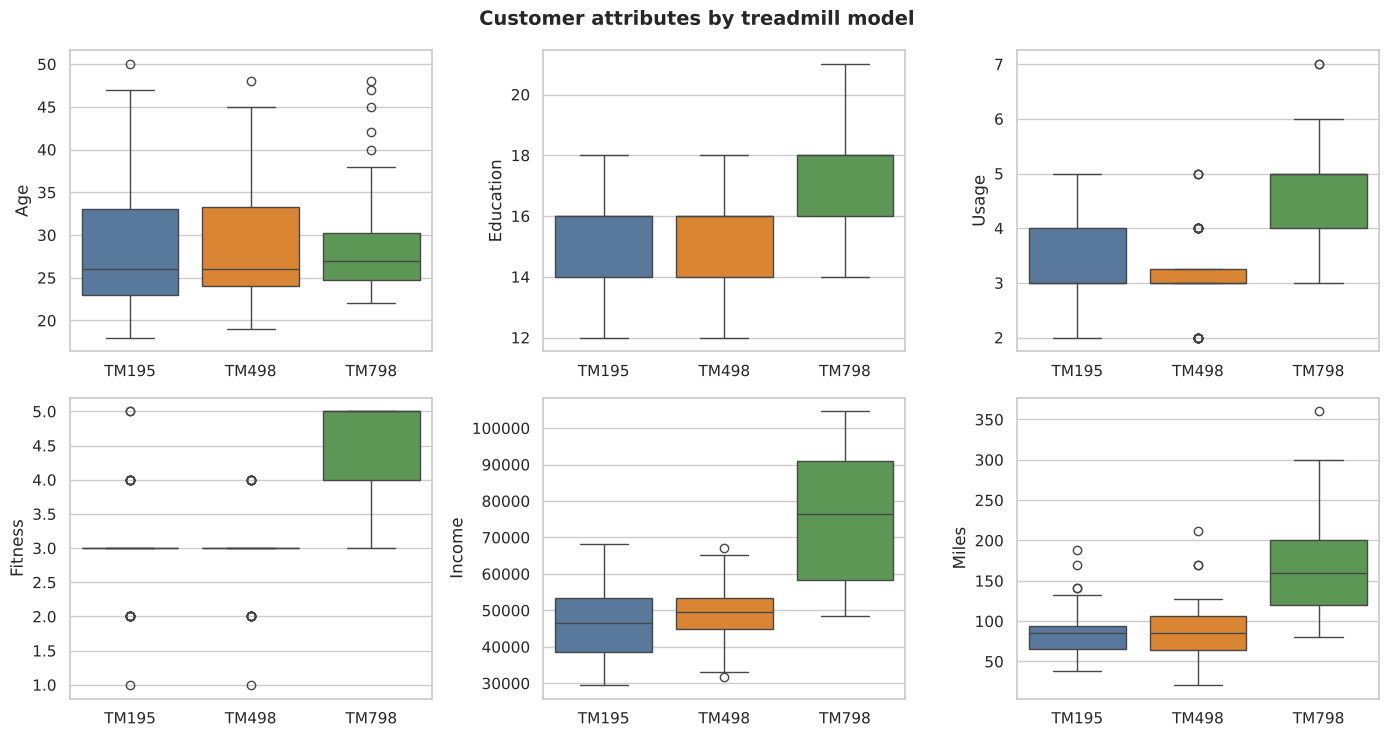

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, NUMERIC):
    sns.boxplot(data=df, x="Product", y=col, order=ORDER, hue="Product", palette=PALETTE, legend=False, ax=ax)
    ax.set_xlabel("")
fig.suptitle("Customer attributes by treadmill model", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("images/attributes_by_product.png", dpi=150, bbox_inches="tight")

**TM195 and TM498 buyers are almost the same**: median age 26, 16 years of education, 3 uses a week, fitness 3, about 85 miles a week, and income around $46k–$49k.

**TM798 buyers are different on every activity and income measure**: median income $76.6k, 18 years of education, 5 uses a week, fitness 5 and 160 miles a week. Age is the one measure that does not separate the products.

## 4. Who buys the TM798?

In [7]:
high_income = df["Income"] > 70000
print(f"Customers earning over $70k: {high_income.sum()}")
print(pd.crosstab(df.loc[high_income, "Product"], "customers").reindex(ORDER, fill_value=0))
print()
print("Product by fitness rating (customers):")
pd.crosstab(df["Fitness"], df["Product"])[ORDER]

Customers earning over $70k: 23
col_0    customers
Product           
TM195            0
TM498            0
TM798           23

Product by fitness rating (customers):


Product,TM195,TM498,TM798
Fitness,,,
1,1,1,0
2,14,12,0
3,54,39,4
4,9,8,7
5,2,0,29


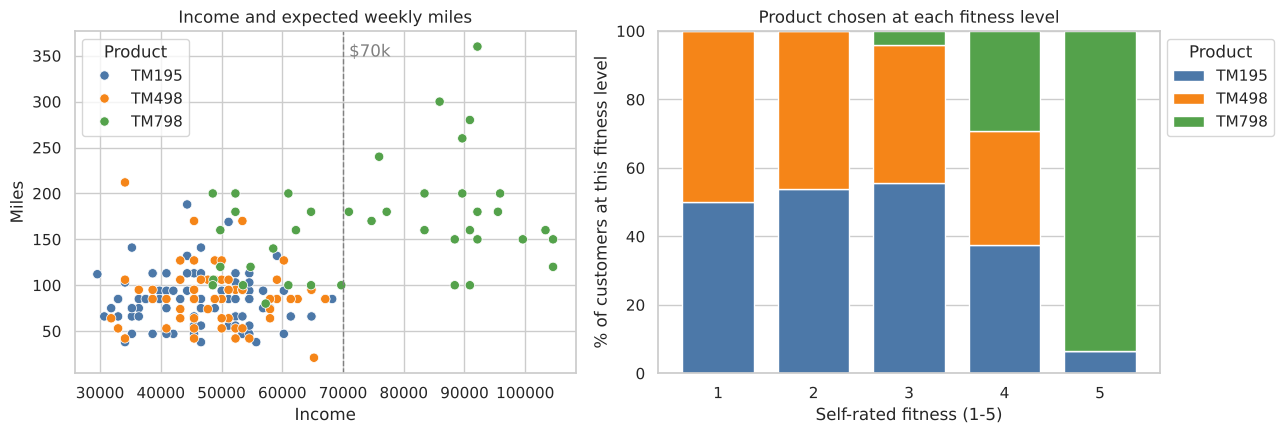

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="Income", y="Miles", hue="Product", hue_order=ORDER, palette=PALETTE, s=45, ax=axes[0])
axes[0].axvline(70000, color="grey", ls="--", lw=1)
axes[0].text(71000, df["Miles"].max() * 0.97, "$70k", color="grey")
axes[0].set_title("Income and expected weekly miles")
fit = pd.crosstab(df["Fitness"], df["Product"], normalize="index")[ORDER] * 100
fit.plot(kind="bar", stacked=True, color=[PALETTE[p] for p in ORDER], ax=axes[1], width=0.75)
axes[1].set_ylabel("% of customers at this fitness level")
axes[1].set_xlabel("Self-rated fitness (1-5)")
axes[1].set_title("Product chosen at each fitness level")
axes[1].legend(title="Product", bbox_to_anchor=(1, 1))
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig("images/tm798_buyers.png", dpi=150, bbox_inches="tight")

## 5. Gender and marital status

In [9]:
by_gender = (pd.crosstab(df["Gender"], df["Product"], normalize="index")[ORDER] * 100).round(1)
by_status = (pd.crosstab(df["MaritalStatus"], df["Product"], normalize="index")[ORDER] * 100).round(1)
print("Product chosen, % of each gender")
print(by_gender, "\n")
print("Product chosen, % of each marital status")
print(by_status)

Product chosen, % of each gender
Product  TM195  TM498  TM798
Gender                      
Female    52.6   38.2    9.2
Male      38.5   29.8   31.7 

Product chosen, % of each marital status
Product        TM195  TM498  TM798
MaritalStatus                     
Partnered       44.9   33.6   21.5
Single          43.8   32.9   23.3


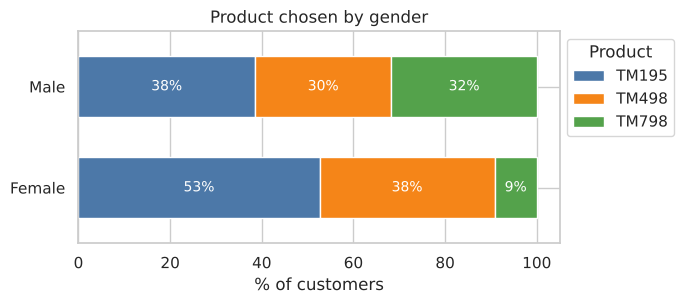

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
by_gender.plot(kind="barh", stacked=True, color=[PALETTE[p] for p in ORDER], ax=ax, width=0.6)
for i, (g, row) in enumerate(by_gender.iterrows()):
    left = 0
    for p in ORDER:
        ax.text(left + row[p] / 2, i, f"{row[p]:.0f}%", ha="center", va="center", color="white", fontsize=10)
        left += row[p]
ax.set_xlabel("% of customers"); ax.set_ylabel("")
ax.set_title("Product chosen by gender")
ax.legend(title="Product", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig("images/product_by_gender.png", dpi=150, bbox_inches="tight")

## 6. How the measures relate

,Age,Education,Usage,Fitness,Income,Miles
Age,1.00,0.28,0.02,0.06,0.51,0.04
Education,0.28,1.00,0.40,0.41,0.63,0.31
Usage,0.02,0.40,1.00,0.67,0.52,0.76
Fitness,0.06,0.41,0.67,1.00,0.54,0.79
Income,0.51,0.63,0.52,0.54,1.00,0.54
Miles,0.04,0.31,0.76,0.79,0.54,1.00


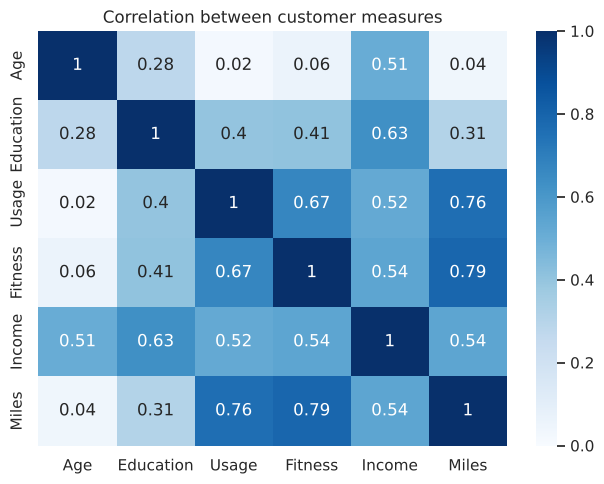

In [11]:
corr = df[NUMERIC].corr().round(2)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Correlation between customer measures")
fig.tight_layout()
fig.savefig("images/correlations.png", dpi=150, bbox_inches="tight")
corr

Planned usage, expected miles and self-rated fitness move together (correlations 0.67–0.79), and income is moderately related to all of them (about 0.5). Age is only related to income (0.51).

## 7. Findings and suggestions

| Product | Typical customer | Suggested positioning |
|---|---|---|
| **TM195** (44% of sales) | Median age 26, income about $46.6k, uses it 3 times a week, fitness 3, 85 miles a week; equal numbers of men and women | Entry-level, value-for-money model for everyday home fitness |
| **TM498** (33%) | Almost identical to TM195: income about $49.5k, 3 uses a week, fitness 3 | Mid-range model; needs a clearer difference from TM195, since its buyers look the same |
| **TM798** (22%) | Income about $76.6k, 18 years of education, 5 uses a week, fitness 5, 160 miles a week; 82.5% men | Premium model for serious runners and high earners |

- **Every customer earning over $70k bought the TM798** (23 customers), and no TM195 or TM498 buyer earned over $68.3k.
- **29 of the 31 customers who rate their fitness 5 bought the TM798.**
- **Women rarely bought the TM798** (7 of 76 women, 9.2%) compared with men (33 of 104, 31.7%). Marketing the premium model to fit, high-income women could be an opportunity, though the data can't show whether this reflects preference or how the model was sold.
- Marital status makes no real difference to the product chosen.

## Limitations
- 180 customers from one retailer, with no prices, dates or store information, so the patterns describe these buyers rather than all treadmill customers.
- Fitness, usage and miles are what customers expected or reported at purchase, not measured use.
- The groups are small (40 TM798 buyers, 7 women among them), so percentages for subgroups are uncertain.